# Análise de erros

Onde o sistema final (híbrido + LambdaMART) erra, por quê, e o que isso diz sobre as limitações. Tudo na **validação** (96 buscas); o teste não é tocado.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from product_search import config
from product_search.engine import SearchEngine
from product_search.evaluation.metrics import evaluate, ndcg, paired_bootstrap, recall
from product_search.evaluation.runs import build_frame, load_dataset, ranked_run
from product_search.ranking.experimental import ATTRIBUTE_KINDS, product_table
from product_search.retrieval.fusion import rrf, top_k
from product_search.text import tokenize

sns.set_theme(style="whitegrid", context="notebook")
LABELS = ["Exact", "Partial", "Irrelevant", "não julgado"]
PALETTE = {"Exact": "#2a9d8f", "Partial": "#e9c46a", "Irrelevant": "#adb5bd", "não julgado": "#e76f51"}

data = load_dataset()
qrels = data.qrels
engine = SearchEngine.load()
pids = engine.products.product_id.to_numpy()
val = data.queries["val"].set_index("query_id")

frame = build_frame(engine, val.reset_index(), qrels, "hybrid")
runs = {"híbrido": ranked_run(frame), "híbrido + LTR": ranked_run(frame, engine.ranker.predict(frame))}
scores = {name: evaluate(run, qrels) for name, run in runs.items()}
best = {qid: g.sort_values("label", ascending=False, kind="stable").product_id.tolist() for qid, g in frame.groupby("query_id")}

q = val.join(scores["híbrido + LTR"]).join(scores["híbrido"]["ndcg@10"].rename("ndcg_hybrid"))
q["oracle"] = [ndcg(best[qid], qrels[qid]) for qid in q.index]
q["n_exact"] = [sum(label == "Exact" for label in qrels[qid].values()) for qid in q.index]
means = q[["ndcg_hybrid", "ndcg@10", "oracle"]].mean()
print(f"{len(q)} buscas | híbrido {means.ndcg_hybrid:.3f} | LTR {means['ndcg@10']:.3f} | oráculo {means.oracle:.3f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4467.93it/s]

96 buscas | híbrido 0.758 | LTR 0.786 | oráculo 0.944


## 1. Onde se perde: achar ou ordenar?

O **oráculo** é a melhor ordem possível dos 100 candidatos. O que falta do oráculo até 1 é perda do **retrieval** (o produto certo nem chegou). O que falta do sistema até o oráculo é perda do **ranking** (estava lá, mas ficou mal colocado).

{'ranking': 46, 'retrieval': 31, 'só Partial julgado': 19}


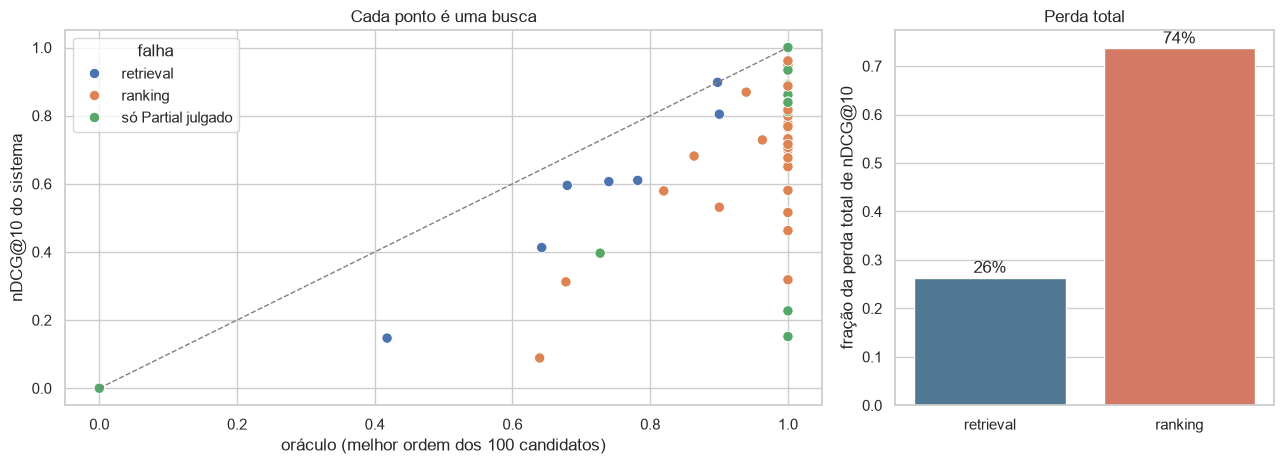

In [2]:
q["perda_retrieval"] = 1 - q.oracle
q["perda_ranking"] = q.oracle - q["ndcg@10"]
q["falha"] = np.select([q.n_exact == 0, q.perda_retrieval >= q.perda_ranking], ["só Partial julgado", "retrieval"], "ranking")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2, 1]})
sns.scatterplot(q, x="oracle", y="ndcg@10", hue="falha", palette="deep", s=55, ax=axes[0])
axes[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
axes[0].set(xlabel="oráculo (melhor ordem dos 100 candidatos)", ylabel="nDCG@10 do sistema", title="Cada ponto é uma busca")
total = pd.Series({"retrieval": q.perda_retrieval.sum(), "ranking": q.perda_ranking.sum()})
sns.barplot(x=total.index, y=total / total.sum(), palette=["#457b9d", "#e76f51"], hue=total.index, legend=False, ax=axes[1])
axes[1].set(xlabel="", ylabel="fração da perda total de nDCG@10", title="Perda total")
for i, v in enumerate(total / total.sum()):
    axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.tight_layout()
print(q.falha.value_counts().to_dict())

**Conclusão.** A maior parte da perda (74%) está em ordenar, não em achar. A nuvem de pontos em oráculo = 1 mostra isso: os produtos certos estavam entre os 100 candidatos, mas o sistema ficou entre 0,3 e 0,9. Por busca, 46 têm mais perda no ranking, 31 no retrieval, e 19 não têm nenhum Exact julgado (só Partial).

## 2. O LTR busca a busca

O ganho médio do LTR sobre a ordem do híbrido vem de muitas buscas ou de poucas? Quantas pioram?

{'melhora': 36, 'empata (±0,01)': 46, 'piora': 14}
ganho médio 0.0276 {'diff': np.float64(0.0276), 'ci95': [np.float64(0.0088), np.float64(0.0473)]}


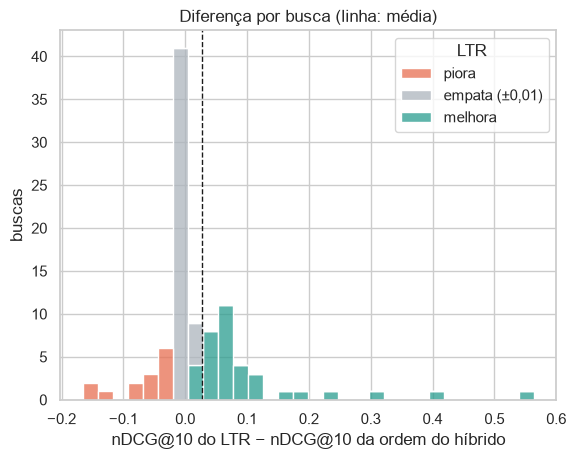

In [3]:
q["diff_ltr"] = q["ndcg@10"] - q.ndcg_hybrid
bucket = pd.cut(q.diff_ltr, [-1, -0.01, 0.01, 1], labels=["piora", "empata (±0,01)", "melhora"]).rename("LTR")
print(bucket.value_counts().reindex(["melhora", "empata (±0,01)", "piora"]).to_dict())
print("ganho médio", round(q.diff_ltr.mean(), 4), paired_bootstrap(q.ndcg_hybrid, q["ndcg@10"]))

colors = {"piora": "#e76f51", "empata (±0,01)": "#adb5bd", "melhora": "#2a9d8f"}
ax = sns.histplot(q, x="diff_ltr", hue=bucket, palette=colors, bins=30, multiple="stack")
ax.axvline(q.diff_ltr.mean(), c="k", ls="--", lw=1)
ax.set(xlabel="nDCG@10 do LTR − nDCG@10 da ordem do híbrido", ylabel="buscas", title="Diferença por busca (linha: média)");

**Conclusão.** O ganho médio de +0,028 (IC [+0,009; +0,047]) não vem de todas as buscas: o LTR melhora 36, empata em 46 e piora 14. A distribuição tem cauda longa à direita: poucas buscas ganham muito (até +0,56), e as pioras são pequenas (no máximo −0,17).

## 3. Recall@k: 100 candidatos bastam?

Fração dos Exact recuperados até a posição k, para cada retriever. Onde a curva achata, mais candidatos custam latência sem trazer produtos novos.

retriever,BM25,denso,híbrido
k,,,
10,0.275,0.260,0.294
20,0.389,0.346,0.378
50,0.553,0.467,0.543
100,0.668,0.589,0.677
200,0.760,0.713,0.783
300,0.800,0.758,0.826
500,0.855,0.816,0.880


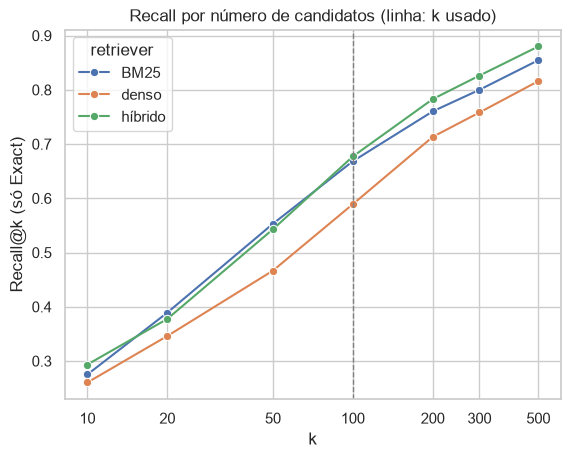

In [4]:
KS = [10, 20, 50, 100, 200, 300, 500]
rows = []
for qid, text in val["query"].items():
    bm25, cosine = engine.bm25.scores(text), engine.dense.scores(text)
    lists = {"BM25": top_k(bm25, max(KS)), "denso": top_k(cosine, max(KS))}
    for k in KS:
        hybrid = rrf([lists["BM25"][:k], lists["denso"][:k]], k)
        for name, idx in {**{n: ranked[:k] for n, ranked in lists.items()}, "híbrido": hybrid}.items():
            rows.append({"retriever": name, "k": k, "recall": recall(pids[idx].tolist(), qrels[qid], k)})
curve = pd.DataFrame(rows).dropna()

ax = sns.lineplot(curve, x="k", y="recall", hue="retriever", marker="o", errorbar=None)
ax.axvline(config.N_CANDIDATES, c="grey", ls="--", lw=1)
title = "Recall por número de candidatos (linha: k usado)"
ax.set(xscale="log", xticks=KS, xticklabels=KS, ylabel="Recall@k (só Exact)", title=title)
curve.pivot_table(index="k", columns="retriever", values="recall").round(3)

**Conclusão.** A curva não achata em 100. Com 200 candidatos, o híbrido recupera 0,783 dos Exact, contra 0,677 com 100 (+0,106). O híbrido também se afasta do BM25 a partir de 200 (+0,02). Mesmo assim, o oráculo com 100 candidatos já chega a 0,944 de nDCG@10, porque a maioria das buscas tem Exact e Partial de sobra no top 100. Mais candidatos ajudariam sobretudo as buscas com poucos Exact, ao custo de calcular features para o dobro de produtos.

## 4. O que vai para o topo

Rótulo do produto em cada posição do top 10. "Não julgado" conta como irrelevante no nDCG@10, mas pode ser um produto relevante que ninguém avaliou.

rótulo,Exact,Partial,Irrelevant,não julgado
sistema,,,,
híbrido,0.355,0.485,0.039,0.121
híbrido + LTR,0.368,0.504,0.042,0.086


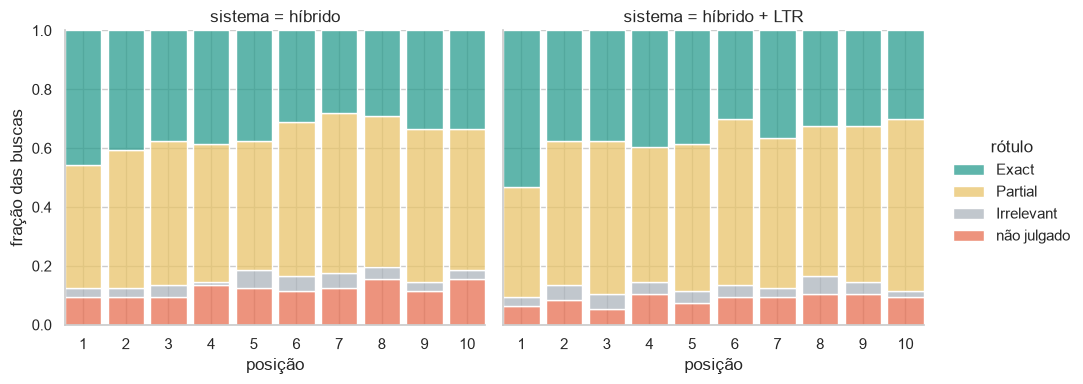

In [5]:
rows = [
    {"sistema": name, "posição": i + 1, "rótulo": qrels[qid].get(p, "não julgado")}
    for name, run in runs.items()
    for qid, ranked in run.items()
    for i, p in enumerate(ranked[:10])
]
top = pd.DataFrame(rows)
g = sns.displot(
    top,
    x="posição",
    hue="rótulo",
    hue_order=LABELS,
    col="sistema",
    multiple="fill",
    discrete=True,
    palette=PALETTE,
    shrink=0.85,
    height=4,
    aspect=1.2,
)
g.set_axis_labels("posição", "fração das buscas").set(xticks=range(1, 11))
pd.crosstab(top.sistema, top["rótulo"], normalize="index").reindex(columns=LABELS).round(3)

**Conclusão.** O LTR aumenta os Exact no topo (de 35,5% para 36,8% do top 10) e, principalmente, reduz os não julgados (de 12,1% para 8,6%). Os Irrelevant julgados quase não mudam (~4%). Ou seja, boa parte do ganho do LTR vem de trocar produtos não julgados por julgados: é por isso que o nDCG condensado, que ignora os não julgados, não muda.

## 5. Em que tipo de busca o sistema é fraco

nDCG@10 do sistema final por segmento (ponto: média; barra: IC 95% por bootstrap).

count   mean
segmento                 valor              
Exact julgados           0–5       44  0.785
                         21+       42  0.800
                         6–20      10  0.732
palavra fora do catálogo não       90  0.802
                         sim        6  0.553
palavras                 1          8  0.867
                         2         23  0.736
                         3         26  0.728
                         4+        39  0.838
pede cor/material/estilo não       70  0.788
                         sim       26  0.780
tem número               não       88  0.779
                         sim        8  0.861

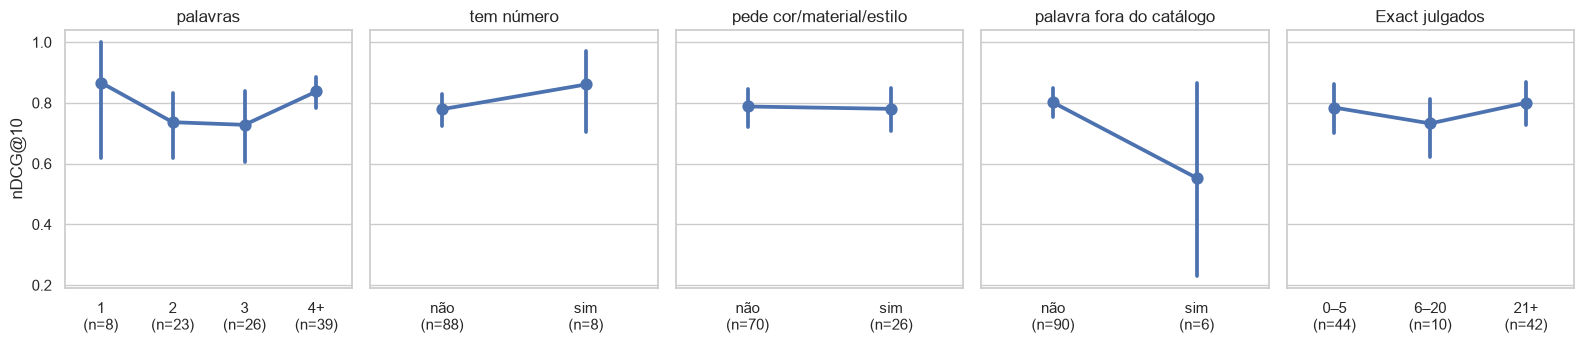

In [6]:
vocab = product_table(engine.products)["vocab"]
known = set(engine.bm25.vectorizer.vocabulary_)
tokens = val["query"].map(tokenize)
q["palavras"] = pd.Categorical(tokens.map(len).clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4+"}), ["1", "2", "3", "4+"])
q["tem número"] = val["query"].str.contains(r"\d").map({True: "sim", False: "não"})
asks_attribute = tokens.map(lambda t: any(set(t) & vocab[k] for k in ATTRIBUTE_KINDS))
q["pede cor/material/estilo"] = asks_attribute.map({True: "sim", False: "não"})
q["palavra fora do catálogo"] = tokens.map(lambda t: any(w not in known for w in t)).map({True: "sim", False: "não"})
q["Exact julgados"] = pd.cut(q.n_exact, [-1, 5, 20, 10_000], labels=["0–5", "6–20", "21+"])

SEGMENTS = ["palavras", "tem número", "pede cor/material/estilo", "palavra fora do catálogo", "Exact julgados"]
ORDER = {"palavras": ["1", "2", "3", "4+"], "Exact julgados": ["0–5", "6–20", "21+"]}
long = q[SEGMENTS + ["ndcg@10"]].astype({s: str for s in SEGMENTS})
long = long.melt(id_vars="ndcg@10", var_name="segmento", value_name="valor")
fig, axes = plt.subplots(1, len(SEGMENTS), figsize=(16, 3.6), sharey=True)
for ax, seg in zip(axes, SEGMENTS, strict=True):
    part = long[long.segmento == seg]
    order = ORDER.get(seg, ["não", "sim"])
    sns.pointplot(part, x="valor", y="ndcg@10", order=order, errorbar=("ci", 95), seed=config.SEED, ax=ax)
    counts = part.valor.value_counts()
    labels = [f"{v}" + chr(10) + f"(n={counts.get(v, 0)})" for v in order]
    ax.set(title=seg, xlabel="", ylabel="nDCG@10", xticks=range(len(order)), xticklabels=labels)
plt.tight_layout()
long.groupby(["segmento", "valor"], observed=True)["ndcg@10"].agg(["count", "mean"]).round(3)

**Conclusão.** O segmento mais fraco é o de **buscas com palavra fora do catálogo** (erros de digitação, palavras coladas, nomes próprios): nDCG@10 de 0,553 contra 0,802, embora sejam só 6 buscas e o IC seja largo. Buscas de 2 e 3 palavras ficam abaixo das de 1 e de 4 ou mais, provavelmente porque concentram as buscas genéricas ("bedroom accessories", "living room designs"). Pedir cor, material ou estilo não muda o resultado, o que bate com a v2 não ter ganhado nada com features de atributo.

## 6. As piores buscas

As 20 buscas com menor nDCG@10, com a falha da seção 1 e as palavras que não existem no catálogo.

In [7]:
product_class = engine.products.set_index("product_id").product_class
worst = q.nsmallest(20, "ndcg@10").assign(
    fora_do_catalogo=lambda d: d["query"].map(lambda s: ", ".join(w for w in tokenize(s) if w not in known)),
    top3=lambda d: [" | ".join(product_class[runs["híbrido + LTR"][qid][:3]].astype(str)) for qid in d.index],
)
pd.set_option("display.max_colwidth", 70)
worst[["query", "query_class", "ndcg@10", "oracle", "recall@100", "n_exact", "falha", "fora_do_catalogo", "top3"]].round(3)

,query,query_class,ndcg@10,oracle,recall@100,n_exact,falha,fora_do_catalogo,top3
query_id,,,,,,,,,
222,small loving roomtables,NaN,0.000,0.000,0.000,31,retrieval,roomtable,| Garden Statues | Planters
383,minnestrista,Wall Art,0.000,0.000,NaN,0,só Partial julgado,minnestrista,| Bars & Bar Sets | Dining Table Sets
173,bedroom accessories,Bath Accessories,0.089,0.639,0.000,4,ranking,,Bed Accessories | Bed Accessories | Bed Accessories
142,kitchen wooden stand,Specialty Serving,0.147,0.418,0.200,5,retrieval,,Plant & Telephone Tables | Plant & Telephone Tables | Kitchen Islands
427,lowes tile,Floor & Wall Tile,0.152,1.000,NaN,0,só Partial julgado,,Floor & Wall Tile | Floor & Wall Tile | Floor & Wall Tile
218,wand bunk beds,NaN,0.227,1.000,NaN,0,só Partial julgado,,Kids Beds | Kids Beds | Kids Beds
460,small wardrobe grey,Armoires & Wardrobes,0.312,0.678,0.143,7,ranking,,Armoires & Wardrobes | Armoires & Wardrobes | Coat Racks and Hooks
449,living room designs,Living Room Sets,0.318,1.000,0.189,164,ranking,,| | Living Room Sets
386,alter furniture,Outdoor Conversation Sets,0.396,0.727,NaN,0,só Partial julgado,,Accent Chests / Cabinets | Bedding Sets | Outdoor Conversation Sets


**Conclusão.** As piores buscas caem em poucos padrões:

- **Palavra fora do catálogo:** "small loving roomtables" (palavra colada), "minnestrista" e "benjiamino" (nomes). O BM25 não tem o que casar, e o denso não compensa.
- **Intenção de inspiração ou categoria ampla:** "living room designs", "wainscoting ideas", "bedroom accessories", "entertainment console". Há muitos produtos possíveis, e o top 10 escolhe outros.
- **Só Partial julgado:** em "lowes tile" e "wand bunk beds" o oráculo é 1, mas o top 10 do LTR é quase todo de produtos não julgados (seção 7).

Correção ortográfica e de palavras coladas atacaria o primeiro grupo sem LLM.

## 7. Não julgados no topo

As buscas em que o LTR mais colocou produtos não julgados no top 10, com esses produtos ao lado de um Exact da mesma busca. O dataset não diz se eles são relevantes: a tabela serve para julgar a olho.

In [8]:
names = engine.products.set_index("product_id").product_name
q["nao_julgados"] = 1 - q["judged@10"]
examples = []
for qid in q.nlargest(6, "nao_julgados").index:
    unjudged = [p for p in runs["híbrido + LTR"][qid][:10] if p not in qrels[qid]]
    exact = [p for p, label in qrels[qid].items() if label == "Exact"][:1]
    examples.append(
        {
            "busca": val.loc[qid, "query"],
            "não julgados no top 10": len(unjudged),
            "exemplos não julgados": " | ".join(names[unjudged[:3]]),
            "um Exact julgado": " | ".join(names[exact]) or "—",
        }
    )
pd.DataFrame(examples)

,busca,não julgados no top 10,exemplos não julgados,um Exact julgado
0,small loving roomtables,10,need a cocktail coffee table | lighted fairy house garden statue |...,abernethy solid wood end table
1,minnestrista,10,alexionna l-shape desk | corene sixteenth century italian replica ...,—
2,lowes tile,8,random sized mosaic tile | slender linear mosaic tile | brickmax r...,—
3,bedroom accessories,7,samarth trundle unit | hand hammered metal tissue box cover | mela...,ishiro decorative 5 piece accessory set
4,wand bunk beds,7,senora bunk bed | adamma bunk bed | kenneth twin bunk bed,—
5,living room designs,6,bethnal living room set | emst living room set | rainey 6 piece li...,darl 2 piece living room set


Uma medida objetiva, sem julgar produto a produto: a fração dos produtos do top 10 cuja classe contém a `query_class` da busca, por rótulo. Se os não julgados se parecem com os Exact nessa medida, o nDCG@10 provavelmente subestima o sistema.

não julgados que o LTR tirou do top 10: 56, 36% da classe pedida


mean  count
sistema       rótulo                   
híbrido       Exact        0.616    341
              Irrelevant   0.189     37
              Partial      0.769    463
              não julgado  0.313     99
híbrido + LTR Exact        0.669    353
              Irrelevant   0.150     40
              Partial      0.788    481
              não julgado  0.258     66

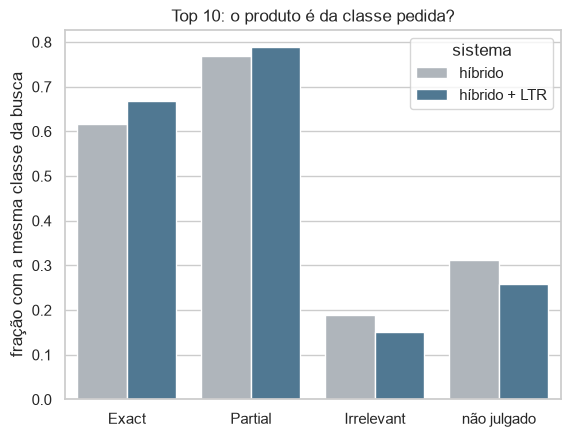

In [9]:
classes = engine.products.set_index("product_id").product_class.str.split("|").map(lambda cs: {c.strip() for c in cs})
same = top.assign(
    query_id=[qid for name, run in runs.items() for qid, ranked in run.items() for _ in ranked[:10]],
    query_class=[val.query_class.get(qid) for name, run in runs.items() for qid, ranked in run.items() for _ in ranked[:10]],
    product_id=[p for name, run in runs.items() for qid, ranked in run.items() for p in ranked[:10]],
).dropna(subset=["query_class"])
same["mesma classe"] = [qc in classes[p] for qc, p in zip(same.query_class, same.product_id, strict=True)]
ax = sns.barplot(same, x="rótulo", y="mesma classe", hue="sistema", order=LABELS, errorbar=None, palette=["#adb5bd", "#457b9d"])
ax.set(xlabel="", ylabel="fração com a mesma classe da busca", title="Top 10: o produto é da classe pedida?")

key = same.query_id.astype(str) + "/" + same.product_id.astype(str)
unjudged = same["rótulo"] == "não julgado"
removed = same[unjudged & (same.sistema == "híbrido") & ~key.isin(key[unjudged & (same.sistema == "híbrido + LTR")])]
print(f"não julgados que o LTR tirou do top 10: {len(removed)}, {removed['mesma classe'].mean():.0%} da classe pedida")
same.groupby(["sistema", "rótulo"])["mesma classe"].agg(["mean", "count"]).round(3)

**Conclusão.** Os não julgados se parecem mais com erros do que com acertos: só 26% dos que ficam no top 10 do LTR são da classe pedida, contra 67% dos Exact e 15% dos Irrelevant. Dos 56 não julgados que o LTR tirou do top 10 do híbrido, só 36% eram da classe pedida, contra 62% dos Exact no topo do híbrido. Então o ganho do LTR no nDCG@10 provavelmente é, em boa parte, real, e não só efeito de pooling. Há exceções visíveis na tabela acima ("wand bunk beds", "living room designs"), em que os não julgados têm nome do produto pedido. A medida é aproximada: a `query_class` é ela mesma imperfeita (um terço dos Exact está fora dela).

## 8. Quanto a validação consegue detectar

Com 96 buscas, qual a menor diferença de nDCG@10 que o bootstrap distingue de zero? E quanto o modelo decora o treino?

In [10]:
half_width = {}
for name, a, b in [("LTR vs. ordem do híbrido", q.ndcg_hybrid, q["ndcg@10"])]:
    ci = paired_bootstrap(a, b)["ci95"]
    half_width[name] = round((ci[1] - ci[0]) / 2, 4)
metrics = json.loads((config.REPORTS / "ranking" / "metrics.json").read_text(encoding="utf-8"))
print("meia largura do IC 95%:", half_width)
print("desvio padrão da diferença por busca:", round(q.diff_ltr.std(), 3))
print({"treino": metrics["train"]["ndcg@10"], "validação": metrics["val"]["base"]["ndcg@10"]})

meia largura do IC 95%: {'LTR vs. ordem do híbrido': np.float64(0.0192)}
desvio padrão da diferença por busca: 0.095
{'treino': 0.8734, 'validação': 0.786}


**Conclusão.** Com 96 buscas, a meia largura do IC da diferença é ~0,019, e o desvio padrão da diferença por busca é 0,095. Diferenças menores que ~0,02 não são distinguíveis de zero, e por isso as variantes da v2 (+0,006) e da v3 nunca passariam, mesmo que fossem melhores de verdade. O modelo também decora o treino: 0,873 contra 0,786 na validação.

## Conclusões

| Achado | Evidência | O que faria |
|---|---|---|
| A perda está em ordenar | 74% da perda; muitas buscas com oráculo 1 e sistema abaixo de 0,7 | Features que separem Exact de Partial; mais buscas julgadas para treinar |
| Buscas com palavra fora do catálogo falham | nDCG@10 0,553 contra 0,802 | Correção ortográfica e de palavras coladas, com o vocabulário do catálogo |
| 100 candidatos não esgotam o recall | 0,677 com 100, 0,783 com 200 | Testar 200 candidatos, medindo a latência do ranking |
| O ganho do LTR provavelmente é real | Não julgados retirados do topo são, em sua maioria, de outra classe | Julgar uma amostra dos não julgados para confirmar |
| A validação só detecta diferenças grandes | IC de ±0,02 com 96 buscas | Validação cruzada (já usada na v3) ou mais buscas |